# 📉 Task 2 · Unemployment Analysis with Python

**Oasis Infobyte Internship (OIBSIP) · Data Science Track**
**Intern:** Vinay Singh Chaudhary  |  **Batch:** 5 Oct – 15 Nov 2026

---

### 🎯 Objective
Perform exploratory data analysis (EDA) on Indian unemployment data to uncover **regional and temporal trends**,
with a special focus on the **impact of the COVID-19 pandemic** (national lockdown from **25 March 2020**).

### 📦 Dataset — *"Unemployment in India"* (Kaggle, source: CMIE)
| File | Period | Rows | Used for |
|------|--------|------|----------|
| `data/Unemployment_in_India.csv` | May 2019 – Jun 2020 | 768 (28 blank) | Main analysis, pre vs post COVID, Rural vs Urban |
| `data/Unemployment_Rate_upto_11_2020.csv` | Jan 2020 – Oct 2020 | 267 | Extended 2020 trend & zone-wise view |

**Columns:** `Region` (state), `Date` (month-end), `Frequency`, `Estimated Unemployment Rate (%)`,
`Estimated Employed`, `Estimated Labour Participation Rate (%)`, `Area` (Rural / Urban).

### 🗺️ Workflow
Load → Inspect & clean → Region-wise EDA → Monthly trend → Time series of major states → Top-10 states →
Correlation heatmap → **Pre-COVID vs COVID comparison** → Rural vs Urban → Zone view → Conclusions

## 1️⃣ Setup

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
os.makedirs("outputs", exist_ok=True)       # all charts are saved here as PNG
LOCKDOWN_DATE = pd.Timestamp("2020-03-25")  # India's nationwide COVID-19 lockdown began on this date
print("✅ Setup complete")

✅ Setup complete


## 2️⃣ Load the data & inspect shape, nulls and types

In [2]:
raw = pd.read_csv("data/Unemployment_in_India.csv")

print("Shape:", raw.shape)
print("\nColumn names exactly as stored (note the leading spaces!):")
print(list(raw.columns))
raw.head()

Shape: (768, 7)

Column names exactly as stored (note the leading spaces!):
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
raw.info()
print("\nNull values per column:\n", raw.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB

Null values per column:
 Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Esti

> **Observations before cleaning**
> - Column names carry **leading spaces** (e.g. `' Date'`) — we strip them.
> - **28 rows are completely empty** (every column is null) — they carry no information, so we drop them.
> - `Date` is stored as **text** (`' 31-05-2019'`) → must be converted to `datetime`.
> - `Frequency` has two spellings (`'Monthly'` / `' Monthly'`) → strip whitespace.

## 3️⃣ Data cleaning & type conversion

In [4]:
df = raw.copy()

# 1) Strip spaces from column names and give them short, code-friendly names
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate",
})

# 2) Drop the fully-empty rows
df = df.dropna(how="all")

# 3) Strip whitespace inside every text column
for col in ["Region", "Date", "Frequency", "Area"]:
    df[col] = df[col].str.strip()

# 4) Convert Date text → real datetime (day-month-year format)
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

# 5) Helper columns for time-based analysis
df["Month"] = df["Date"].dt.to_period("M").astype(str)       # e.g. '2020-04'
df["Period"] = np.where(df["Date"] < LOCKDOWN_DATE, "Pre-COVID", "COVID (post-lockdown)")

print("Shape after cleaning:", df.shape)
print("Remaining nulls:", int(df.isnull().sum().sum()))
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df["Date"].min().date(), "→", df["Date"].max().date())
print("States / UTs:", df["Region"].nunique())
df.dtypes

Shape after cleaning: (740, 9)
Remaining nulls: 0
Duplicate rows: 0
Date range: 2019-05-31 → 2020-06-30
States / UTs: 28


Region                                  str
Date                         datetime64[us]
Frequency                               str
Unemployment_Rate                   float64
Employed                            float64
Labour_Participation_Rate           float64
Area                                    str
Month                                   str
Period                                  str
dtype: object

In [5]:
# Descriptive statistics of the three numeric indicators
df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].describe().round(2)

,Unemployment_Rate,Employed,Labour_Participation_Rate
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.50
max,76.74,45777509.00,72.57


> **Observation:** After cleaning we have **740 rows, 0 nulls, 28 states/UTs, 14 months**.
> Unemployment ranges from **0 % to ~76 %** — the extreme values all belong to April–May 2020 (lockdown months).

## 4️⃣ EDA — region-wise average unemployment

In [6]:
# Average unemployment rate per state across the whole period (Rural + Urban combined)
region_avg = (df.groupby("Region")["Unemployment_Rate"].mean()
                .sort_values(ascending=False).round(2))
print("Average unemployment rate by state (%):")
region_avg.to_frame("Avg Unemployment Rate (%)")

Average unemployment rate by state (%):


,Avg Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


## 5️⃣ EDA — month-wise national trend

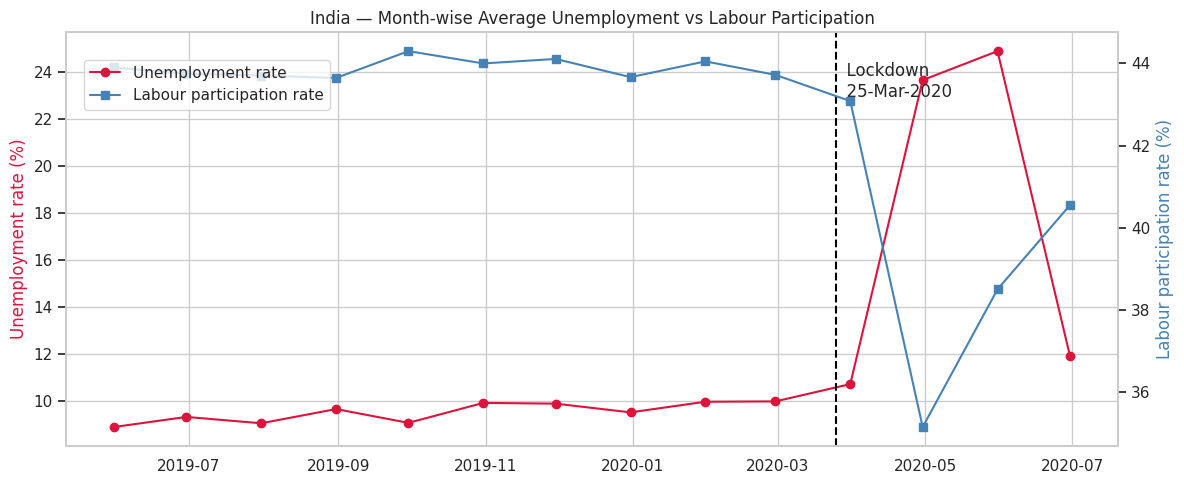

Date,2019-05-31,2019-06-30,2019-07-31,2019-08-31,2019-09-30,2019-10-31,2019-11-30,2019-12-31,2020-01-31,2020-02-29,2020-03-31,2020-04-30,2020-05-31,2020-06-30
Unemployment_Rate,8.87,9.30,9.03,9.64,9.05,9.9,9.87,9.50,9.95,9.96,10.70,23.64,24.88,11.90
Labour_Participation_Rate,43.90,43.75,43.71,43.65,44.30,44.0,44.11,43.67,44.05,43.72,43.08,35.14,38.50,40.55


In [7]:
# National average for each month (mean across all states and both areas)
monthly = df.groupby("Date")[["Unemployment_Rate", "Labour_Participation_Rate"]].mean()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(monthly.index, monthly["Unemployment_Rate"], marker="o", color="crimson", label="Unemployment rate")
ax1.set_ylabel("Unemployment rate (%)", color="crimson")
ax2 = ax1.twinx()                                    # second y-axis for participation rate
ax2.plot(monthly.index, monthly["Labour_Participation_Rate"], marker="s", color="steelblue", label="Labour participation rate")
ax2.set_ylabel("Labour participation rate (%)", color="steelblue")
ax2.grid(False)                                     # avoid a second, clashing grid
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
ax1.axvline(LOCKDOWN_DATE, ls="--", color="black")
ax1.text(LOCKDOWN_DATE, ax1.get_ylim()[1] * 0.95, "  Lockdown\n  25-Mar-2020", va="top")
ax1.set_title("India — Month-wise Average Unemployment vs Labour Participation")
fig.tight_layout()
plt.savefig("outputs/01_monthly_trend.png", dpi=120, bbox_inches="tight")
plt.show()

monthly.round(2).T

> **Observation:** From May 2019 to Feb 2020 unemployment is stable at **~9–10 %**.
> It **more than doubles to ~24–25 % in April–May 2020**, exactly when the lockdown hit, while labour participation drops —
> many people stopped even looking for work. By June 2020 (unlock phase) the rate falls back to ~12 %.

## 6️⃣ Time-series line chart — major states

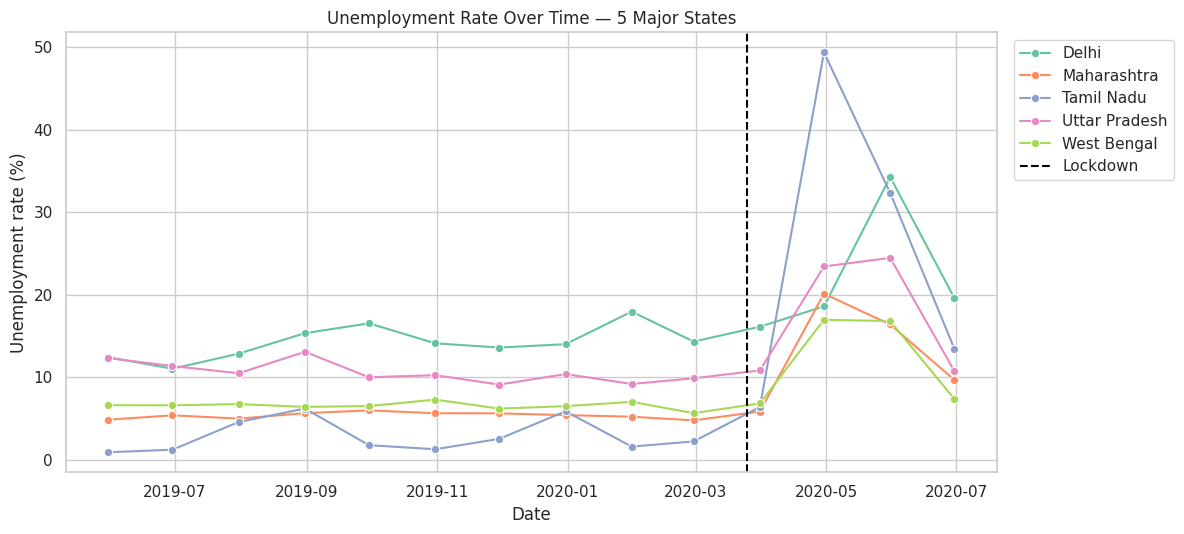

In [8]:
# Combine Rural+Urban into one state-level value per month
state_month = df.groupby(["Region", "Date"])["Unemployment_Rate"].mean().reset_index()

major_states = ["Maharashtra", "Uttar Pradesh", "Tamil Nadu", "Delhi", "West Bengal"]
plt.figure(figsize=(12, 5.5))
sns.lineplot(data=state_month[state_month["Region"].isin(major_states)],
             x="Date", y="Unemployment_Rate", hue="Region", marker="o")
plt.axvline(LOCKDOWN_DATE, ls="--", color="black", label="Lockdown")
plt.title("Unemployment Rate Over Time — 5 Major States")
plt.ylabel("Unemployment rate (%)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("outputs/02_state_timeseries.png", dpi=120, bbox_inches="tight")
plt.show()

> **Observation:** Every major state shows the same lockdown spike, but its **size differs**:
> Tamil Nadu jumps from ≈ 6 % to **≈ 49 % in April 2020**, Delhi peaks at ≈ 34 % in May, while Maharashtra and West Bengal peak at a milder ≈ 17–20 %.
> The *timing* also differs — Delhi's peak comes a month later — showing that lockdown impact depended on each state's economy and restrictions.

## 7️⃣ Bar chart — top 10 states with the highest average unemployment

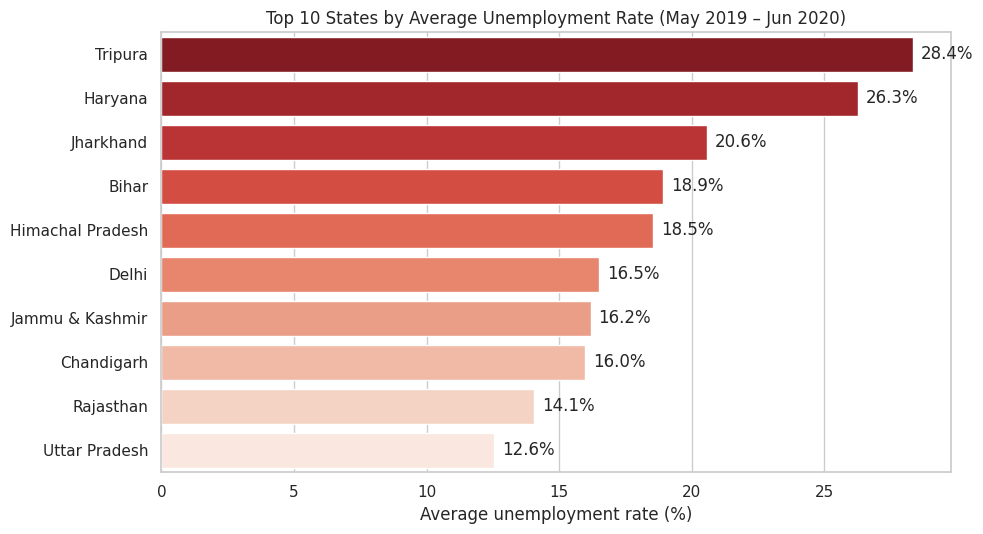

In [9]:
top10 = region_avg.head(10)
plt.figure(figsize=(10, 5.5))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette="Reds_r", legend=False)
for i, v in enumerate(top10.values):
    plt.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.title("Top 10 States by Average Unemployment Rate (May 2019 – Jun 2020)")
plt.xlabel("Average unemployment rate (%)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("outputs/03_top10_states.png", dpi=120, bbox_inches="tight")
plt.show()

> **Observation:** **Tripura (≈ 28 %)** and **Haryana (≈ 26 %)** top the list, followed by Jharkhand, Bihar and Himachal Pradesh.
> These states had high unemployment even before COVID — the pandemic amplified an existing structural problem.

## 8️⃣ Correlation heatmap

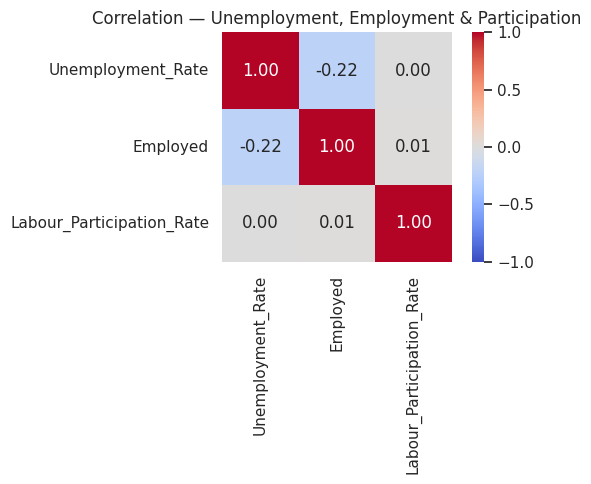

In [10]:
corr = df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation — Unemployment, Employment & Participation")
plt.tight_layout()
plt.savefig("outputs/04_correlation_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

> **Observation:** Correlations across all states are **weak** (unemployment vs employed ≈ −0.22; vs participation ≈ 0).
> This is because `Employed` is an *absolute count* driven mostly by **state population** (UP has far more workers than Tripura),
> which hides the relationship. Within a single state over time the link is much stronger — see the monthly chart above,
> where participation falls as unemployment rises.

## 9️⃣ Pre-COVID vs COVID comparison

,Pre-COVID,COVID (post-lockdown),% change
Unemployment_Rate,9.51,17.77,86.91
Labour_Participation_Rate,43.89,39.33,-10.38
"Employed (millions, avg per row)",7.47,6.52,-12.71


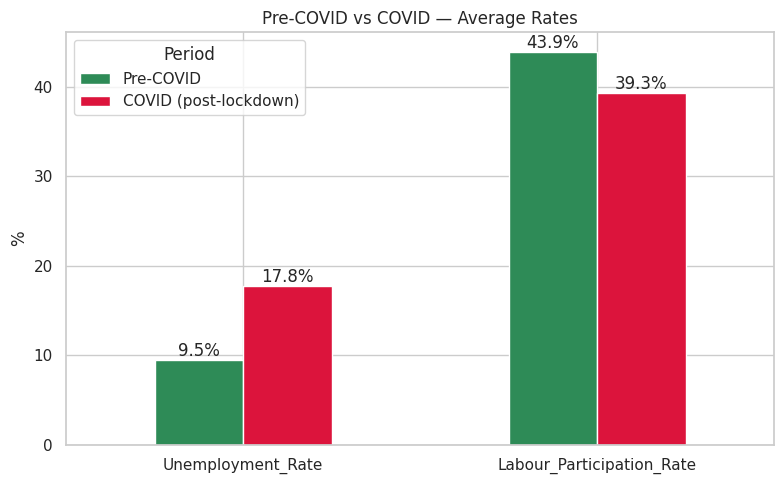

In [11]:
# Split at the lockdown date and compare the mean of every indicator
period_cmp = (df.groupby("Period")[["Unemployment_Rate", "Labour_Participation_Rate", "Employed"]]
                .mean().reindex(["Pre-COVID", "COVID (post-lockdown)"]))
period_cmp["Employed"] = period_cmp["Employed"] / 1e6            # show employed in millions
period_cmp = period_cmp.rename(columns={"Employed": "Employed (millions, avg per row)"})
change = ((period_cmp.iloc[1] - period_cmp.iloc[0]) / period_cmp.iloc[0] * 100).rename("% change")
display(pd.concat([period_cmp.T, change], axis=1).round(2))

# Side-by-side bars of the mean unemployment and participation rate
ax = period_cmp[["Unemployment_Rate", "Labour_Participation_Rate"]].T.plot(kind="bar", figsize=(8, 5), rot=0,
                                                                          color=["seagreen", "crimson"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
ax.set_title("Pre-COVID vs COVID — Average Rates")
ax.set_ylabel("%")
plt.tight_layout()
plt.savefig("outputs/05_pre_vs_post_covid.png", dpi=120, bbox_inches="tight")
plt.show()

In [12]:
# Which states were hit hardest? (increase in average unemployment, percentage points)
state_period = df.pivot_table(index="Region", columns="Period", values="Unemployment_Rate", aggfunc="mean")
state_period["Increase (pp)"] = state_period["COVID (post-lockdown)"] - state_period["Pre-COVID"]
state_period.sort_values("Increase (pp)", ascending=False).round(2).head(10)

Period,COVID (post-lockdown),Pre-COVID,Increase (pp)
Region,,,
Puducherry,38.96,1.59,37.36
Tamil Nadu,25.40,2.84,22.57
Jharkhand,36.35,14.28,22.07
Bihar,31.63,13.83,17.80
Karnataka,15.28,3.23,12.05
Haryana,34.65,22.94,11.72
Kerala,17.95,6.99,10.96
Telangana,15.44,4.66,10.79
Madhya Pradesh,14.07,4.74,9.33


> **Observation:** The average unemployment rate rose from **≈ 9.5 % before COVID to ≈ 17.8 % after the lockdown — an ~87 % jump** —
> while labour participation fell by ≈ 4.6 points (−10 %) and the average number employed fell by ≈ 13 %.
> **Puducherry, Tamil Nadu, Jharkhand, Bihar and Karnataka** saw the largest increases (+12 to +37 percentage points).

## 🔟 Rural vs Urban

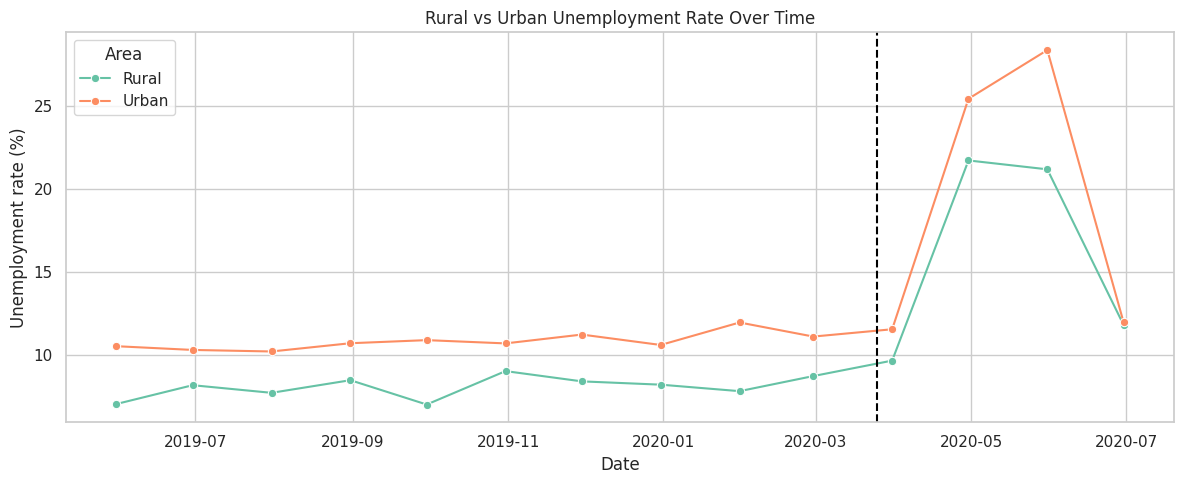

Period,COVID (post-lockdown),Pre-COVID
Area,,
Rural,16.18,8.09
Urban,19.28,10.84


In [13]:
area_month = df.groupby(["Date", "Area"])["Unemployment_Rate"].mean().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(data=area_month, x="Date", y="Unemployment_Rate", hue="Area", marker="o")
plt.axvline(LOCKDOWN_DATE, ls="--", color="black")
plt.title("Rural vs Urban Unemployment Rate Over Time")
plt.ylabel("Unemployment rate (%)")
plt.tight_layout()
plt.savefig("outputs/06_rural_vs_urban.png", dpi=120, bbox_inches="tight")
plt.show()

df.pivot_table(index="Area", columns="Period", values="Unemployment_Rate", aggfunc="mean").round(2)

> **Observation:** Urban unemployment is **consistently higher** than rural (≈ 10.8 % vs 8.1 % before COVID; ≈ 19.3 % vs 16.2 % after).
> Both roughly doubled after the lockdown. Urban services, construction and daily-wage work stopped completely, while agriculture
> in rural areas continued — although returning migrant workers also pushed rural unemployment up.

## 1️⃣1️⃣ Extended 2020 view & zone-wise analysis (second file)

Shape: (267, 9) | nulls: 0


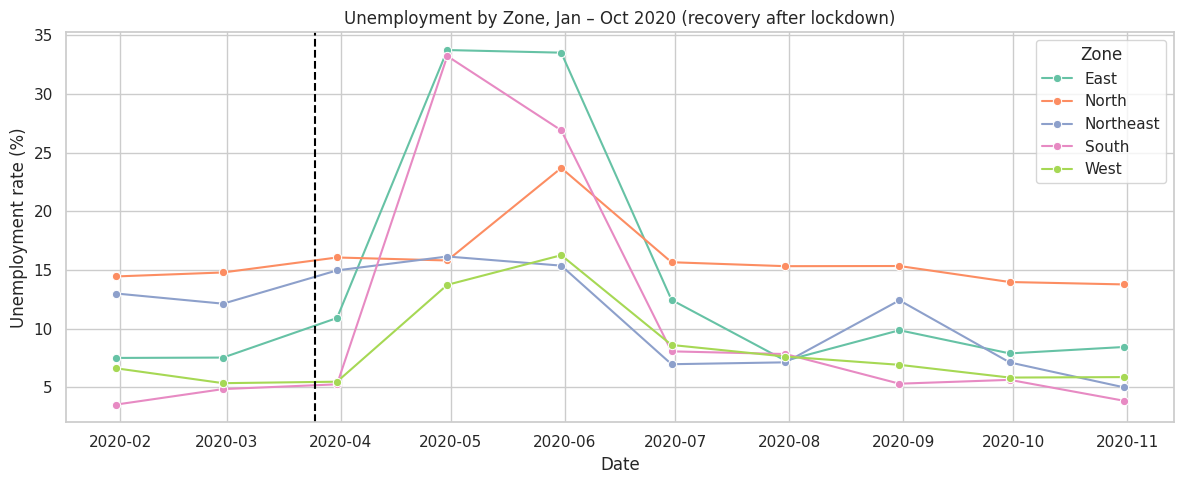

,Avg 2020 rate (%)
Zone,
North,15.89
East,13.92
Northeast,10.95
South,10.45
West,8.24


In [14]:
ext = pd.read_csv("data/Unemployment_Rate_upto_11_2020.csv")
ext.columns = ext.columns.str.strip()
ext = ext.rename(columns={"Estimated Unemployment Rate (%)": "Unemployment_Rate", "Region.1": "Zone"})
ext["Date"] = pd.to_datetime(ext["Date"].str.strip(), format="%d-%m-%Y")
print("Shape:", ext.shape, "| nulls:", int(ext.isnull().sum().sum()))

zone_month = ext.groupby(["Date", "Zone"])["Unemployment_Rate"].mean().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(data=zone_month, x="Date", y="Unemployment_Rate", hue="Zone", marker="o")
plt.axvline(LOCKDOWN_DATE, ls="--", color="black")
plt.title("Unemployment by Zone, Jan – Oct 2020 (recovery after lockdown)")
plt.ylabel("Unemployment rate (%)")
plt.tight_layout()
plt.savefig("outputs/07_zone_trend_2020.png", dpi=120, bbox_inches="tight")
plt.show()

ext.groupby("Zone")["Unemployment_Rate"].mean().sort_values(ascending=False).round(2).to_frame("Avg 2020 rate (%)")

> **Observation:** East and South zones spike to **≈ 33 % in April–May 2020**; the North peaks in May (≈ 24 %).
> By **Jul–Oct 2020** every zone is back near its pre-COVID level. The **North** has the highest 2020 average (≈ 15.9 %) because it was
> already high before COVID (≈ 14–15 %) — a structural issue, not only a pandemic effect. The **West** is lowest (≈ 8.2 %).

## ✅ Conclusions
1. **Stable before COVID:** national unemployment hovered at ~9–10 % from May 2019 to Feb 2020.
2. **Lockdown shock:** it jumped to ~24–25 % in April–May 2020 — the average rate after the lockdown was **~87 % higher** than before.
3. **Uneven impact:** Puducherry, Tamil Nadu, Jharkhand and Bihar were hit hardest; Tripura and Haryana had the highest average rates overall.
4. **Urban > Rural:** urban unemployment is higher at all times; both areas roughly doubled after the lockdown.
5. **Participation fell:** many people left the labour force entirely, so the true job loss is larger than the unemployment rate suggests.
6. **Recovery:** by Aug–Oct 2020 most zones returned close to pre-pandemic levels.

**Future scope:** forecast unemployment with ARIMA/Prophet, map state-level rates on a choropleth using the latitude/longitude columns.

---
*Submitted by **Vinay Singh Chaudhary** for the Oasis Infobyte Data Science Internship · #oasisinfobyte*